# Visualisasi Evaluasi Chunking

Notebook ini fokus pada kualitas hasil retrieval, bukan latensi. Data yang dipakai hanya CSV yang berada langsung di folder `evaluation/chunk_eval_results`, tanpa membaca subfolder `old`.

Grafik yang dibuat:

1. Bar chart NDCG@30 per metode chunking.
2. Bar chart jumlah hasil yang dievaluasi dan matched ground truth.
3. Rank vs relevance untuk melihat kualitas urutan hasil.
4. Cumulative gain untuk melihat akumulasi relevansi di ranking atas.
5. Distribusi relevance score per metode chunking.


In [10]:
from pathlib import Path
import os

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 180,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.titlesize": 12,
    "legend.fontsize": 9,
})

SUMMARY_CSV = "chunking_qq01_summary_ndcg_at_30.csv"
DETAIL_CSV = "chunking_qq01_detail_ndcg_at_30.csv"

# Bisa dijalankan dari root repo atau dari folder notebook.
candidate_dirs = [Path("."), Path("evaluation/chunk_eval_results")]
DATA_DIR = next((p for p in candidate_dirs if (p / SUMMARY_CSV).exists() and (p / DETAIL_CSV).exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Tidak menemukan CSV evaluasi chunking. Jalankan notebook dari root repo atau folder chunk_eval_results.")

csv_files = sorted(DATA_DIR.glob("*.csv"))  # non-recursive, tidak membaca subfolder old
summary = pd.read_csv(DATA_DIR / SUMMARY_CSV)
detail = pd.read_csv(DATA_DIR / DETAIL_CSV)

summary_numeric_cols = [
    "m", "ef_construct", "search_hnsw_ef", "raw_qdrant_limit", "target_k",
    "raw_hit_count", "unique_article_count", "evaluated_rows",
    "matched_gt_rows_at_k", "ndcg_at_30", "elapsed_ms",
]
detail_numeric_cols = [
    "rank_after_eval_filter", "rank_before_eval_filter", "score", "relevance",
    "chunk_index", "total_chunks", "chunk_tokens", "gt_rta_id",
]

for col in summary_numeric_cols:
    if col in summary.columns:
        summary[col] = pd.to_numeric(summary[col], errors="coerce")
for col in detail_numeric_cols:
    if col in detail.columns:
        detail[col] = pd.to_numeric(detail[col], errors="coerce")

summary = summary.sort_values("chunking_method").reset_index(drop=True)
detail = detail.sort_values(["chunking_method", "rank_after_eval_filter"]).reset_index(drop=True)

print(f"Folder data: {DATA_DIR.resolve()}")
print("CSV top-level yang tersedia:")
for path in csv_files:
    print(f"- {path.name}")


Folder data: /home/vinik/Github/vector-search-thesis/evaluation/chunk_eval_results
CSV top-level yang tersedia:
- chunking_qq01_detail_ndcg_at_30.csv
- chunking_qq01_summary_ndcg_at_30.csv


## Ringkasan Data

Cell ini menampilkan data summary utama. Untuk skripsi yang fokus pada kualitas retrieval, metrik paling penting adalah `ndcg_at_30`, `evaluated_rows`, `matched_gt_rows_at_k`, dan urutan `relevance` pada detail result.


In [11]:
summary[[
    "query_id", "query", "chunking_method", "collection_name",
    "evaluated_rows", "matched_gt_rows_at_k", "ndcg_at_30",
    "raw_hit_count", "unique_article_count"
]]


,query_id,query,chunking_method,collection_name,evaluated_rows,matched_gt_rows_at_k,ndcg_at_30,raw_hit_count,unique_article_count
0,Q01,customs clearance for perishable goods,hybrid,rtas_hybrid_m8_ef400,16,16,0.819576,100,97
1,Q01,customs clearance for perishable goods,recursive,rtas_recursive_m8_ef400,13,13,0.752868,100,96


## Grafik 1 - NDCG@30 per Metode Chunking

Ini grafik utama yang paling cocok jika fokus penelitian bukan latensi. NDCG@30 menilai kualitas ranking, sehingga metode yang menempatkan dokumen relevan di posisi atas akan mendapat nilai lebih tinggi.


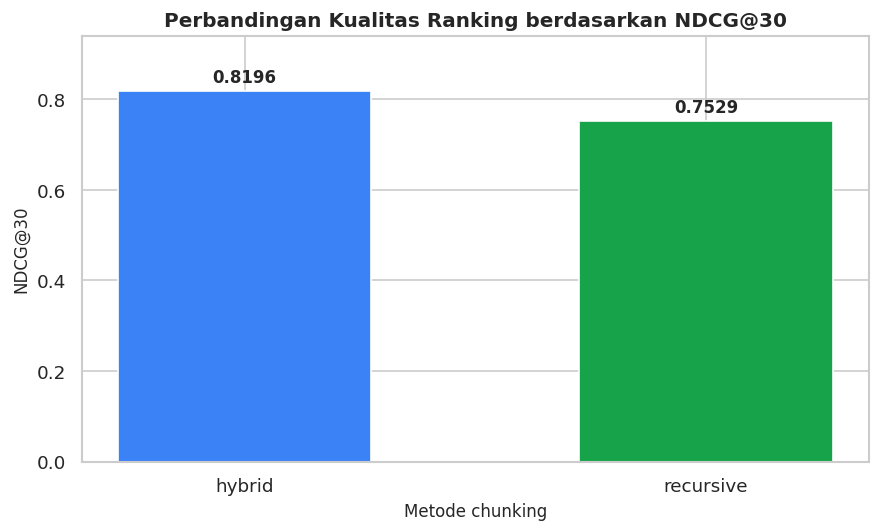

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
colors = ["#3b82f6", "#16a34a", "#f97316", "#9333ea"]
bars = ax.bar(summary["chunking_method"], summary["ndcg_at_30"], color=colors[:len(summary)], width=0.55)

for bar in bars:
    value = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

ax.set_ylim(0, min(1.0, summary["ndcg_at_30"].max() + 0.12))
ax.set_xlabel("Metode chunking")
ax.set_ylabel("NDCG@30")
ax.set_title("Perbandingan Kualitas Ranking berdasarkan NDCG@30")
plt.tight_layout()
plt.show()


## Grafik 2 - Evaluated Rows dan Matched Ground Truth

Grafik ini menjelaskan berapa banyak hasil yang masuk evaluasi dan berapa banyak yang cocok dengan ground truth. Ini berguna sebagai pendamping NDCG karena menunjukkan coverage hasil relevan yang ditemukan oleh setiap metode.


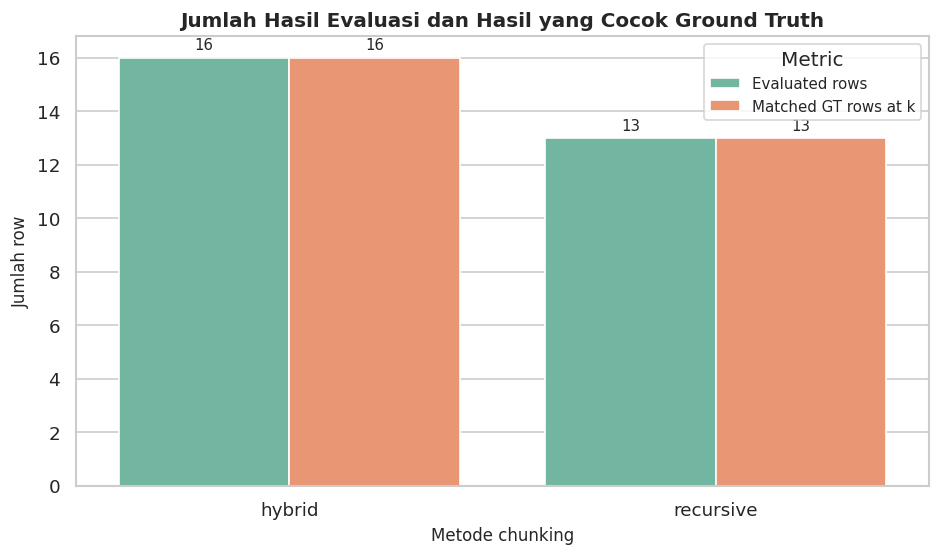

In [13]:
rows_long = summary.melt(
    id_vars="chunking_method",
    value_vars=["evaluated_rows", "matched_gt_rows_at_k"],
    var_name="metric",
    value_name="count",
)
metric_labels = {
    "evaluated_rows": "Evaluated rows",
    "matched_gt_rows_at_k": "Matched GT rows at k",
}
rows_long["metric"] = rows_long["metric"].map(metric_labels)

fig, ax = plt.subplots(figsize=(8, 4.8))
sns.barplot(data=rows_long, x="chunking_method", y="count", hue="metric", palette="Set2", ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=9)

ax.set_xlabel("Metode chunking")
ax.set_ylabel("Jumlah row")
ax.set_title("Jumlah Hasil Evaluasi dan Hasil yang Cocok Ground Truth")
ax.legend(title="Metric", loc="upper right")
plt.tight_layout()
plt.show()


## Grafik 3 - Rank vs Relevance

NDCG dipengaruhi oleh posisi dokumen relevan pada ranking. Grafik ini memperlihatkan nilai relevance pada tiap posisi ranking. Metode yang lebih baik seharusnya mempertahankan relevance tinggi pada ranking awal.


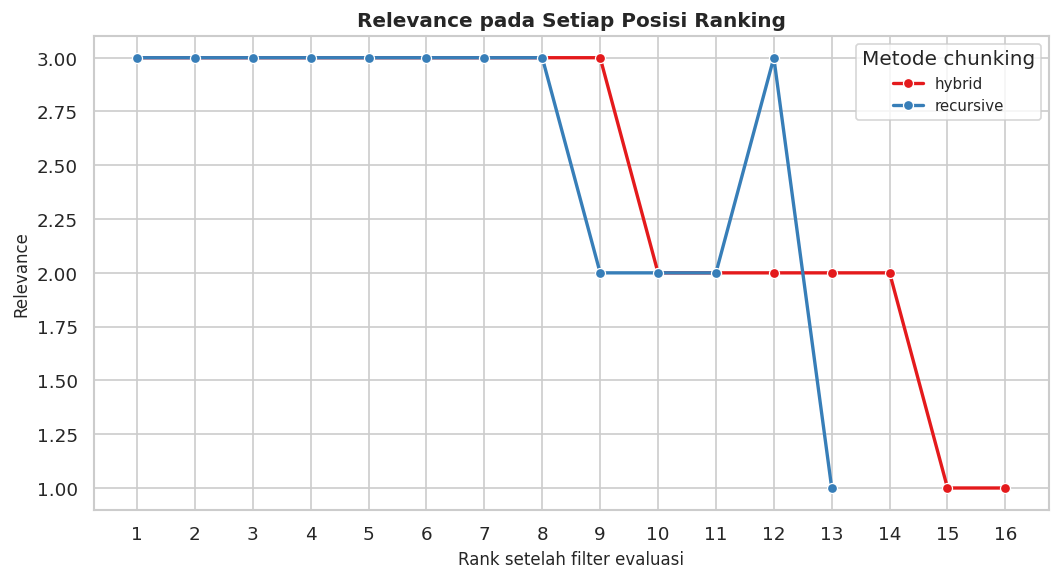

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(
    data=detail,
    x="rank_after_eval_filter",
    y="relevance",
    hue="chunking_method",
    marker="o",
    linewidth=2,
    palette="Set1",
    ax=ax,
)
ax.set_xticks(sorted(detail["rank_after_eval_filter"].dropna().astype(int).unique()))
ax.set_xlabel("Rank setelah filter evaluasi")
ax.set_ylabel("Relevance")
ax.set_title("Relevance pada Setiap Posisi Ranking")
ax.legend(title="Metode chunking")
plt.tight_layout()
plt.show()


## Grafik 4 - Cumulative Gain

Cumulative gain memperlihatkan akumulasi nilai relevance dari rank awal sampai rank ke-k. Semakin cepat kurva naik, semakin cepat metode tersebut menemukan hasil yang relevan di posisi atas.


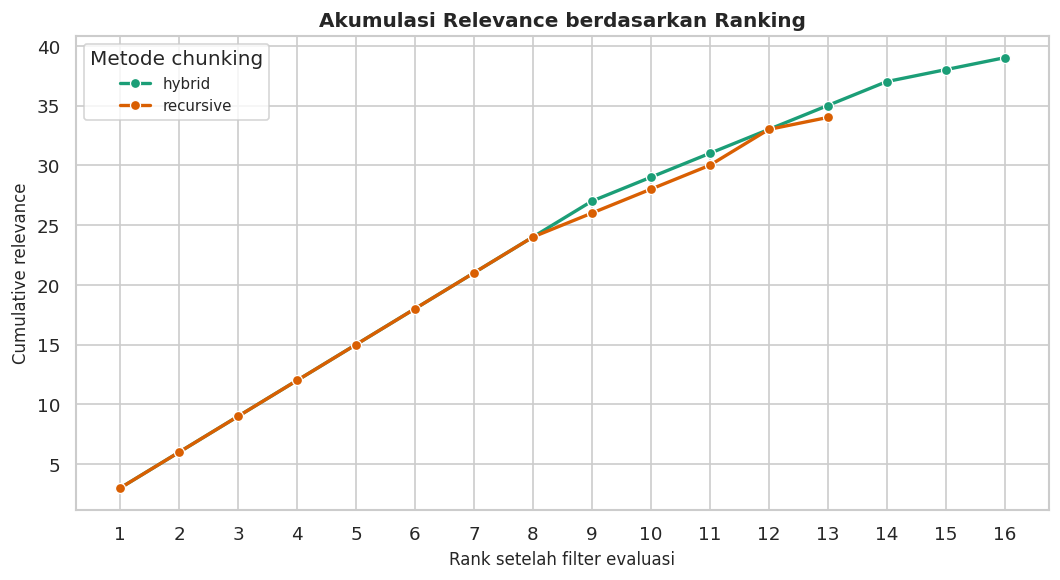

,chunking_method,rank_after_eval_filter,relevance,cumulative_gain
24,recursive,9,2.0,26.0
25,recursive,10,2.0,28.0
26,recursive,11,2.0,30.0
27,recursive,12,3.0,33.0
28,recursive,13,1.0,34.0


In [15]:
gain = detail[["chunking_method", "rank_after_eval_filter", "relevance"]].copy()
gain = gain.sort_values(["chunking_method", "rank_after_eval_filter"])
gain["cumulative_gain"] = gain.groupby("chunking_method")["relevance"].cumsum()

fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(
    data=gain,
    x="rank_after_eval_filter",
    y="cumulative_gain",
    hue="chunking_method",
    marker="o",
    linewidth=2,
    palette="Dark2",
    ax=ax,
)
ax.set_xticks(sorted(gain["rank_after_eval_filter"].dropna().astype(int).unique()))
ax.set_xlabel("Rank setelah filter evaluasi")
ax.set_ylabel("Cumulative relevance")
ax.set_title("Akumulasi Relevance berdasarkan Ranking")
ax.legend(title="Metode chunking")
plt.tight_layout()
plt.show()

gain.tail()


## Grafik 5 - Distribusi Relevance Score

Grafik ini menunjukkan jumlah dokumen pada tiap level relevance. Berbeda dari NDCG, grafik ini tidak memperhitungkan urutan ranking, sehingga sebaiknya dipakai sebagai pendukung.


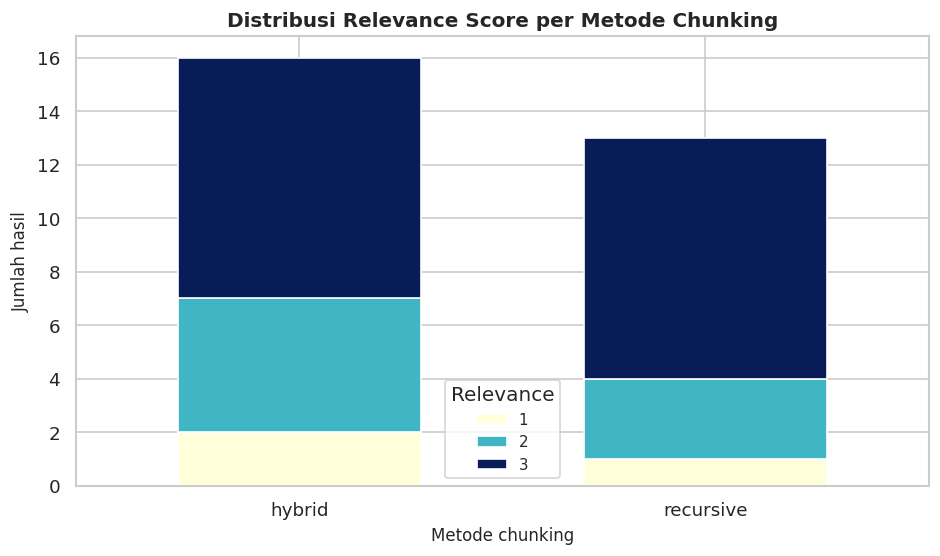

relevance_label,1,2,3
chunking_method,,,
hybrid,2,5,9
recursive,1,3,9


In [16]:
rel_dist = (
    detail.assign(relevance_label=detail["relevance"].astype(int).astype(str))
    .groupby(["chunking_method", "relevance_label"], as_index=False)
    .size()
)
rel_pivot = rel_dist.pivot(index="chunking_method", columns="relevance_label", values="size").fillna(0)
rel_pivot = rel_pivot.reindex(sorted(rel_pivot.columns, key=int), axis=1)

fig, ax = plt.subplots(figsize=(8, 4.8))
rel_pivot.plot(kind="bar", stacked=True, colormap="YlGnBu", ax=ax, width=0.6)

ax.set_xlabel("Metode chunking")
ax.set_ylabel("Jumlah hasil")
ax.set_title("Distribusi Relevance Score per Metode Chunking")
ax.legend(title="Relevance")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

rel_pivot


## Grafik 6 - Score Decay & Hit Mapping

Grafik ini menggunakan data detail ranking dari `chunking_qq01_detail_ndcg_at_30.csv`. Sumbu X menunjukkan posisi ranking hasil evaluasi, sedangkan sumbu Y menunjukkan skor similarity dari Qdrant. Garis memperlihatkan penurunan skor model ketika ranking semakin turun, dan warna marker menunjukkan label relevance dari ground truth.

Catatan: file detail ini sudah menggunakan pendekatan GT-filtered, sehingga baris yang tampil adalah artikel yang masuk ground truth pool. Karena itu, pemetaan hit pada grafik ini direpresentasikan sebagai level `relevance`, bukan hit/non-hit terhadap seluruh kandidat retrieval.


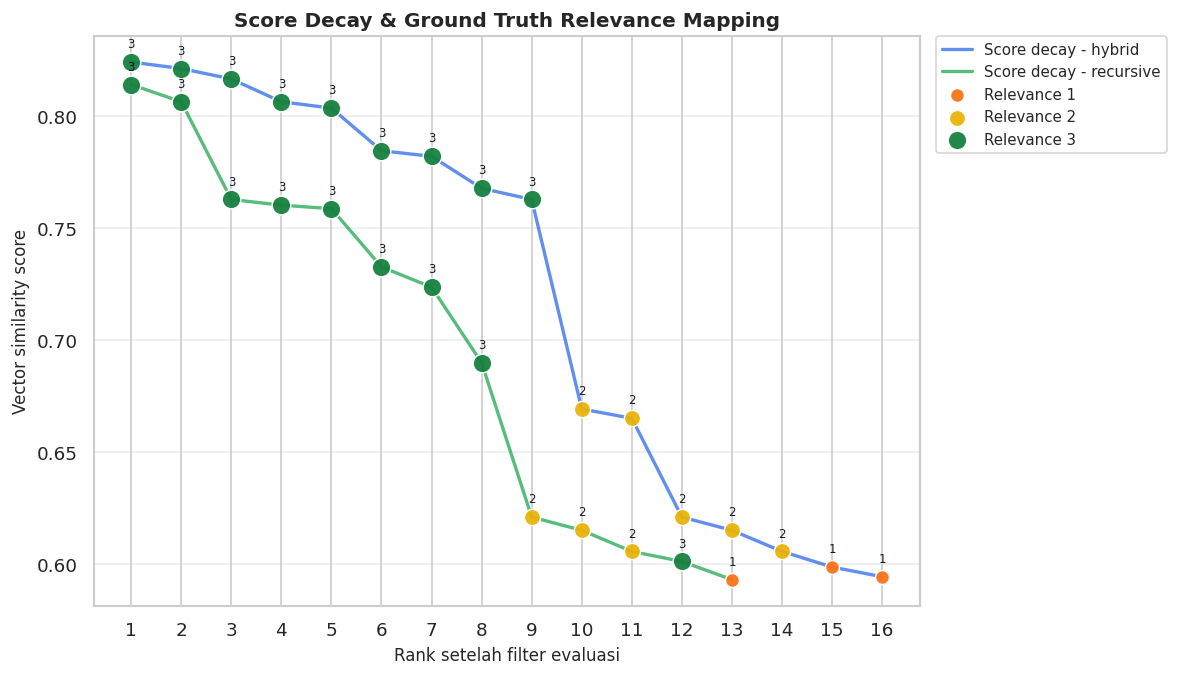

,chunking_method,rank_after_eval_filter,rank_before_eval_filter,score,relevance,chunk_method,chunk_tokens,agreement,article_number,article_name
0,hybrid,1,1,0.824166,3.0,Semantic,103,"China - Hong Kong, China",Article 39,Perishable Goods
1,hybrid,2,2,0.821290,3.0,Semantic,97,"China - Macao, China",Article 39,Perishable Goods
2,hybrid,3,3,0.816619,3.0,Semantic,181,Chile - China,Article 44,Release of Goods
3,hybrid,4,4,0.806459,3.0,Semantic,282,United Kingdom - India,Article 5.6,Perishable Goods
4,hybrid,5,5,0.803620,3.0,Recursive-Fallback,196,"Korea, Republic of - Philippines",Article 5.11,Release of Goods
5,hybrid,6,7,0.784580,3.0,Semantic,242,"Hong Kong, China - Georgia",Article 13,Perishable Goods
6,hybrid,7,8,0.782114,3.0,Recursive-Fallback,242,EFTA - Georgia,Article 4,Simplification of International Trade Procedures
7,hybrid,8,9,0.767821,3.0,Recursive-Fallback,173,Regional Comprehensive Economic Partnership Ag...,Article 4.11,Release of Goods
8,hybrid,9,10,0.762837,3.0,Semantic,239,United Kingdom - New Zealand FTA,Article 4.10,Perishable Goods
9,hybrid,10,30,0.669322,2.0,Semantic,128,"China - Macao, China",Article 38,Release of Goods


In [17]:
score_decay = detail.copy()
score_decay["rank_after_eval_filter"] = pd.to_numeric(score_decay["rank_after_eval_filter"], errors="coerce")
score_decay["score"] = pd.to_numeric(score_decay["score"], errors="coerce")
score_decay["relevance"] = pd.to_numeric(score_decay["relevance"], errors="coerce")
score_decay["relevance_label"] = score_decay["relevance"].fillna(0).astype(int).astype(str)
score_decay = score_decay.sort_values(["chunking_method", "rank_after_eval_filter"])

method_colors = {
    "hybrid": "#2563eb",
    "recursive": "#16a34a",
}
relevance_colors = {
    "0": "#dc2626",
    "1": "#f97316",
    "2": "#eab308",
    "3": "#15803d",
}
relevance_sizes = {
    "0": 45,
    "1": 70,
    "2": 95,
    "3": 125,
}

fig, ax = plt.subplots(figsize=(10, 5.8))

for method, method_df in score_decay.groupby("chunking_method"):
    ax.plot(
        method_df["rank_after_eval_filter"],
        method_df["score"],
        color=method_colors.get(method, "#64748b"),
        linewidth=2,
        alpha=0.72,
        label=f"Score decay - {method}",
    )

for rel_label, rel_df in score_decay.groupby("relevance_label"):
    ax.scatter(
        rel_df["rank_after_eval_filter"],
        rel_df["score"],
        s=relevance_sizes.get(rel_label, 60),
        color=relevance_colors.get(rel_label, "#64748b"),
        edgecolor="white",
        linewidth=0.9,
        alpha=0.94,
        label=f"Relevance {rel_label}",
        zorder=3,
    )

for _, row in score_decay.iterrows():
    ax.annotate(
        str(int(row["relevance"])),
        xy=(row["rank_after_eval_filter"], row["score"]),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=7,
        color="#111827",
    )

ax.set_xlabel("Rank setelah filter evaluasi")
ax.set_ylabel("Vector similarity score")
ax.set_title("Score Decay & Ground Truth Relevance Mapping")
ax.set_xticks(sorted(score_decay["rank_after_eval_filter"].dropna().astype(int).unique()))
ax.grid(True, axis="y", alpha=0.35)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0, frameon=True)
plt.tight_layout()
plt.show()

score_decay[[
    "chunking_method", "rank_after_eval_filter", "rank_before_eval_filter",
    "score", "relevance", "chunk_method", "chunk_tokens",
    "agreement", "article_number", "article_name"
]]


## Grafik Opsional - Komposisi Chunk Method dan Ukuran Chunk

Grafik ini membantu menjelaskan karakteristik hasil retrieval, terutama pada metode hybrid yang dapat berisi `Semantic` dan `Recursive-Fallback`. Ini bukan grafik utama, tetapi bisa membantu analisis mengapa satu metode menghasilkan ranking yang lebih baik.


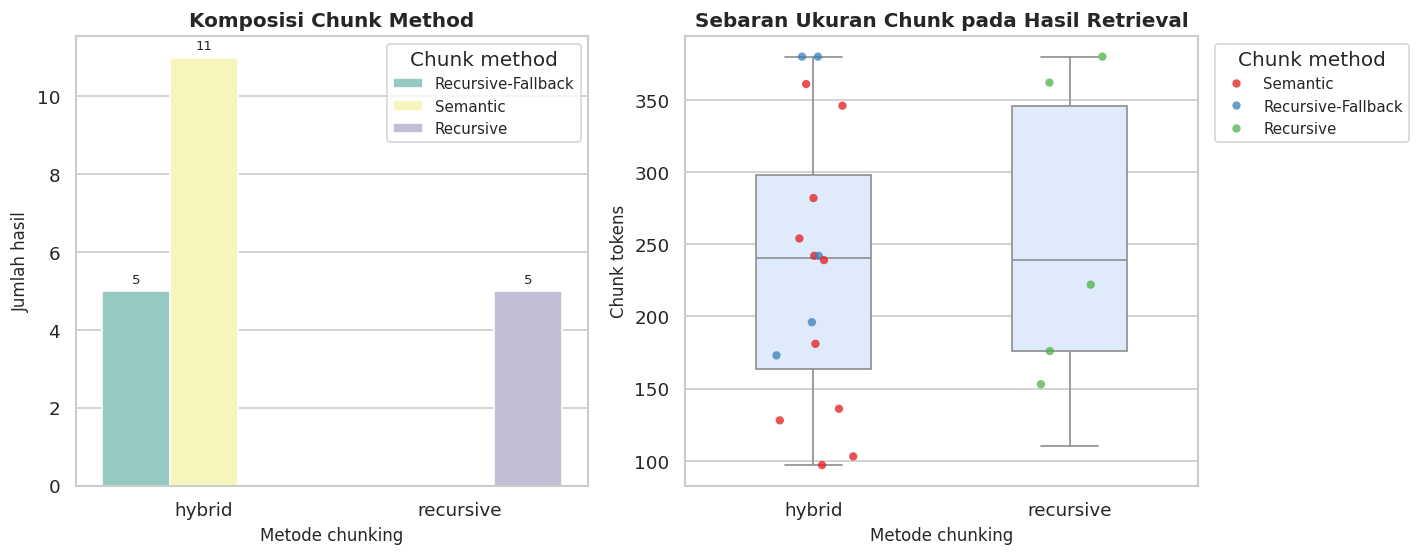

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

chunk_method_counts = (
    detail.groupby(["chunking_method", "chunk_method"], as_index=False)
    .size()
)
sns.barplot(
    data=chunk_method_counts,
    x="chunking_method",
    y="size",
    hue="chunk_method",
    palette="Set3",
    ax=axes[0],
)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=3, fontsize=8)
axes[0].set_xlabel("Metode chunking")
axes[0].set_ylabel("Jumlah hasil")
axes[0].set_title("Komposisi Chunk Method")
axes[0].legend(title="Chunk method")

sns.boxplot(
    data=detail,
    x="chunking_method",
    y="chunk_tokens",
    color="#dbeafe",
    width=0.45,
    showfliers=False,
    ax=axes[1],
)
sns.stripplot(
    data=detail,
    x="chunking_method",
    y="chunk_tokens",
    hue="chunk_method",
    palette="Set1",
    jitter=0.16,
    size=5,
    alpha=0.75,
    ax=axes[1],
)
axes[1].set_xlabel("Metode chunking")
axes[1].set_ylabel("Chunk tokens")
axes[1].set_title("Sebaran Ukuran Chunk pada Hasil Retrieval")
axes[1].legend(title="Chunk method", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()


## Catatan Penulisan untuk Skripsi

Karena fokus penelitian bukan latensi, grafik utama yang paling tepat adalah **NDCG@30 per metode chunking**. Grafik tersebut langsung menjawab metode mana yang menghasilkan ranking paling baik.

Untuk memperkuat analisis, gunakan **rank vs relevance** dan **cumulative gain**. Dua grafik itu menjelaskan bahwa kualitas ranking tidak hanya ditentukan oleh banyaknya dokumen relevan yang ditemukan, tetapi juga oleh posisi dokumen relevan tersebut di ranking atas.

Latensi masih boleh disebut singkat pada tabel summary, tetapi tidak perlu menjadi grafik utama.
